# Karar Ağaçları — Uygulamalı Jupyter Lab
### 10 adım adım Decision Tree uygulaması + 3 yönlendirmeli kümeleme görevi

**Eğitmen sürümü — çözümler dahil** · Python / scikit-learn · Türkçe

**Öğrenme hedefleri:** Decision Tree ile sınıflandırma ve regresyon yapmak; **Entropy, Gini, Information Gain** değerlerini kendiniz hesaplamak; eğitim/test ayrımı, model karmaşıklığı ve metrikleri yorumlamak; son bölümde K-Means ve denetimsiz öğrenmeyi uygulamak.

**Çalışma düzeni:** İlk **10 uygulama** tam çalışan örneklerdir. Kodların **her çalıştırılabilir satırının hemen önünde**, satırın görevini anlatan Türkçe bir yorum vardır. Kodları sırayla çalıştırın, çıktılarını inceleyin ve mini soruları yanıtlayın. Son **3 görev** öğrencinin dolduracağı TODO hücreleriyle bırakılmıştır. Öğretim elemanı için ayrı çözüm notebook'u hazırlanmıştır.

**Not:** Decision Tree **denetimli öğrenme**, K-Means **denetimsiz öğrenme** yöntemidir. Son 3 görev, ayrıca istediğin *kümeleme* bölümüdür; Decision Tree örnekleriyle karıştırılmamalıdır.

**Çalıştırma:** JupyterLab / Jupyter Notebook / VS Code. Yüklü değilse terminalde `pip install numpy pandas matplotlib scikit-learn jupyter` kullanabilirsiniz. Veri kümeleri scikit-learn ile gelir, dosya indirmek gerekmez.

---

## 01. İlk karar ağacımı kuruyorum

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Bir öğrencinin haftalık çalışma saatine göre sınavı geçip geçmeyeceğini tahmin etmek. `0 = Kaldı`, `1 = Geçti`. Girdi matrisi neden iki boyutlu? `fit` ve `predict` ne işe yarar?

In [1]:
# Karar ağacı sınıflandırma modelinin sınıfını içe aktar.
from sklearn.tree import DecisionTreeClassifier
# Her öğrencinin çalışma saatini 1 özellikli bir liste olarak tanımla.
X_1 = [[1], [2], [3], [4], [5], [6]]
# Çalışma sürelerine ait gerçek sınıf etiketlerini aynı sırada yaz.
y_1 = [0, 0, 0, 1, 1, 1]
# Tekrarlanabilir sonuç için sabit rastgelelik ve küçük bir ağaç oluştur.
tree_1 = DecisionTreeClassifier(max_depth=1, random_state=42)
# Karar ağacına girdi ve doğru etiketleri göstererek eğit.
tree_1.fit(X_1, y_1)
# 2.5 saat çalışan yeni bir öğrenciyi iki boyutlu biçimde hazırla.
new_1 = [[2.5]]
# Eğitilmiş ağaçtan yeni örnek için sınıf tahmini al.
prediction_1 = tree_1.predict(new_1)
# Tahmini, anlamlı bir metinle ekrana yazdır.
print('2.5 saat için:', 'Geçti' if prediction_1[0] == 1 else 'Kaldı')
# Ağacın kök düğümde öğrendiği sayısal eşik değerini görüntüle.
print('Öğrenilen eşik:', tree_1.tree_.threshold[0])

2.5 saat için: Kaldı
Öğrenilen eşik: 3.5


**Mini soru:** 4,5 saat çalışan biri için sınıf ne olur? `max_depth=1` olmasının anlamı nedir?

---

## 02. Gerçek veri: Iris ve train/test ayrımı

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Iris çiçeği veri kümesini tanımak, eğitim ve test kümelerini ayırmak. Bir test örneğini eğitim sırasında görmemek neden önemlidir?

In [2]:
# Iris veri kümesini yüklemek için gereken fonksiyonu içe aktar.
from sklearn.datasets import load_iris
# Eğitim/test ayrımını yapacak aracı içe aktar.
from sklearn.model_selection import train_test_split
# Iris veri kümesini, tablo ve sınıf adlarını içerecek biçimde yükle.
iris_2 = load_iris()
# Çiçeklerin sayısal ölçümlerini özellik matrisi olarak al.
X_2 = iris_2.data
# Her çiçeğin türünü gösteren etiketleri hedef vektöre al.
y_2 = iris_2.target
# Sınıf oranlarını koruyarak verinin %20’sini test için ayır.
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X_2, y_2, test_size=0.20, stratify=y_2, random_state=42)
# Eğitim setindeki örnek ve özellik sayısını yaz.
print('Eğitim boyutu:', X_train_2.shape)
# Test setindeki örnek ve özellik sayısını yaz.
print('Test boyutu:', X_test_2.shape)
# Özelliklerin isimlerini yaz; modelin neyle çalıştığını gör.
print('Özellikler:', iris_2.feature_names)
# Tahmin edilecek sınıfların isimlerini göster.
print('Sınıflar:', iris_2.target_names)

Eğitim boyutu: (120, 4)
Test boyutu: (30, 4)
Özellikler: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Sınıflar: ['setosa' 'versicolor' 'virginica']


**Mini soru:** 150 örnek ve 4 özellik varsa `X_train.shape` ve `X_test.shape` ne olmalıdır?

---

## 03. Model eğitimi, tahmin ve sınıf olasılıkları

**Tür:** KOLAY — UYGULAMALI

**Amaç:** 2. uygulamadaki aynı veri ayrımını kullanarak modeli eğitmek ve sınıf olasılıklarını okumak.

In [3]:
# Accuracy metriğini kullanmak için fonksiyonu içe aktar.
from sklearn.metrics import accuracy_score
# Az derinlikli karar ağacı modelini tanımla.
tree_3 = DecisionTreeClassifier(max_depth=3, random_state=42)
# Modeli yalnızca eğitim verisi üzerinde öğren.
tree_3.fit(X_train_2, y_train_2)
# Test kümesindeki çiçeklerin türlerini tahmin et.
pred_3 = tree_3.predict(X_test_2)
# Gerçek ve tahmin edilen etiketler arasından doğruluğu hesapla.
accuracy_3 = accuracy_score(y_test_2, pred_3)
# Test doğruluğunu yüzde biçiminde yazdır.
print(f'Test accuracy: %{accuracy_3 * 100:.1f}')
# İlk test örneğini tek satırlık bir matris olarak ayır.
first_flower_3 = X_test_2[:1]
# İlk örnek için üç sınıfın olasılık tahminlerini hesapla.
prob_3 = tree_3.predict_proba(first_flower_3)
# Tahmin olasılıklarını 3 basamakla görüntüle.
print('Sınıf olasılıkları:', prob_3.round(3))
# Olasılık sütunlarının sıralandığı sınıf kodlarını yazdır.
print('Sınıf kodları:', tree_3.classes_)

Test accuracy: %96.7
Sınıf olasılıkları: [[1. 0. 0.]]
Sınıf kodları: [0 1 2]


**Mini soru:** `predict_proba` çıktısının satır toplamı kaçtır? Test accuracy neden tek başına her zaman yeterli olmayabilir?

---

## 04. Öğrenilen ağacı görselleştirme

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Ağacın karar koşullarını, yapraklarını, Gini değerini ve örnek sayılarını grafik üzerinde bulmak.

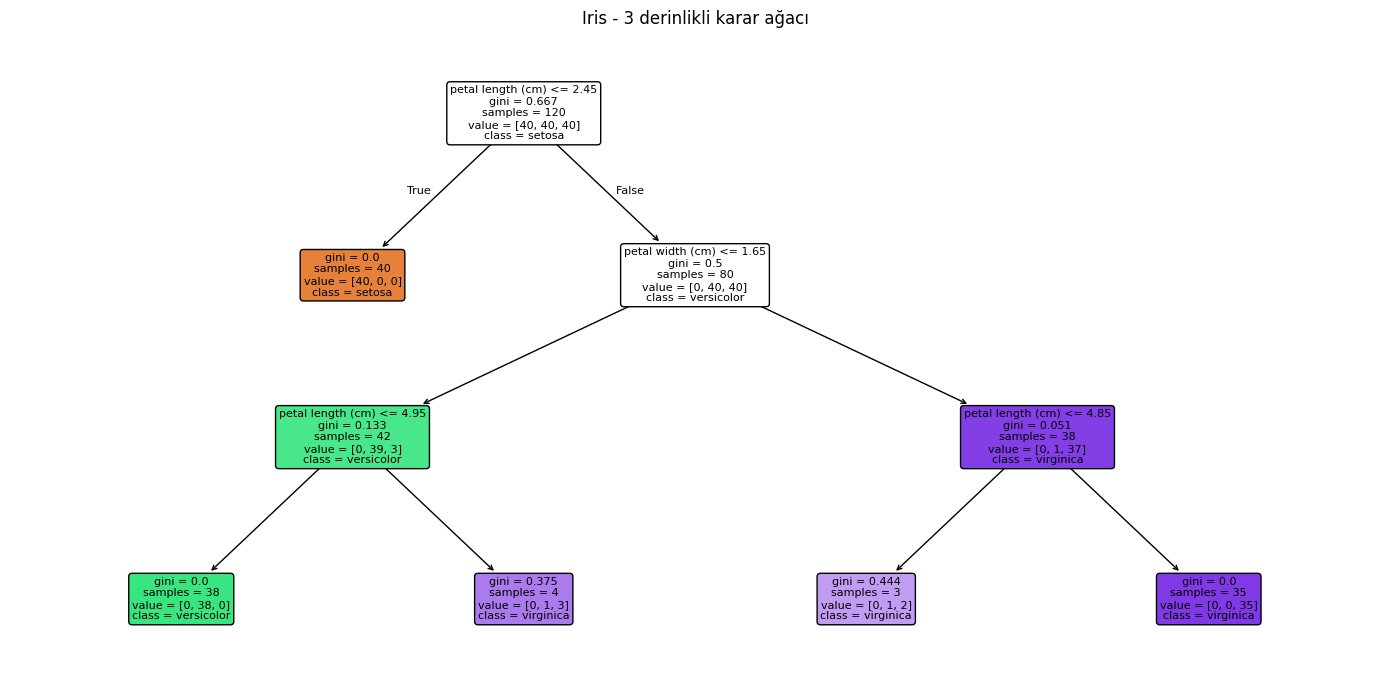

In [4]:
# Grafik çizmek için pyplot modülünü içe aktar.
import matplotlib.pyplot as plt
# Karar ağacını görselleştiren plot_tree fonksiyonunu içe aktar.
from sklearn.tree import plot_tree
# Okunabilir boyutta yeni bir şekil oluştur.
plt.figure(figsize=(14, 7))
# Eğitilmiş ağacı; değişken/sınıf adları ve düğüm renkleriyle çiz.
plot_tree(tree_3, feature_names=iris_2.feature_names, class_names=iris_2.target_names, filled=True, rounded=True, fontsize=8)
# Grafiğin üstüne açıklayıcı bir başlık ekle.
plt.title('Iris - 3 derinlikli karar ağacı')
# Boş kenar boşluklarını düzelt.
plt.tight_layout()
# Oluşturulan karar ağacı grafiğini göster.
plt.show()

**Mini soru:** Kök düğümde hangi özelliğe bakılıyor? `samples`, `value`, `gini`, `class` neyi ifade ediyor?

---

## 05. Entropy ve Gini hesabını elle kodlama

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Pozitif/negatif örnek sayılarından safsızlık ölçütlerini Python ile hesaplamak. Formüller:

\[H=-\sum_i p_i\log_2 p_i,\qquad Gini=1-\sum_i p_i^2\]

`0 × log(0)` terimini matematiksel limit gereği **0** kabul ediyoruz.

In [5]:
# Sayısal hesaplamalar ve logaritma için NumPy içe aktar.
import numpy as np
# Bir düğümde 8 pozitif, 2 negatif örnek olduğunu belirt.
counts_5 = np.array([8, 2])
# Düğümdeki toplam örnek sayısını hesapla.
total_5 = counts_5.sum()
# Her sınıfın sayısını toplam örnek sayısına bölerek olasılığı bul.
p_5 = counts_5 / total_5
# Sıfır olasılıkları logaritmadan çıkararak yalnızca pozitifleri seç.
positive_p_5 = p_5[p_5 > 0]
# Entropi formülündeki tüm p log2(p) terimlerini topla.
entropy_5 = -np.sum(positive_p_5 * np.log2(positive_p_5))
# Gini hesabında 1 eksi kareli olasılıklar toplamını bul.
gini_5 = 1 - np.sum(p_5 ** 2)
# Örneklerin sınıf dağılımı ve olasılıklarını yazdır.
print('Sayılar:', counts_5, '| Olasılıklar:', p_5)
# Entropiyi dört basamakla göster.
print(f'Entropy: {entropy_5:.4f}')
# Gini indeksini dört basamakla göster.
print(f'Gini: {gini_5:.4f}')

Sayılar: [8 2] | Olasılıklar: [0.8 0.2]
Entropy: 0.7219
Gini: 0.3200


**Mini soru:** `counts_5 = np.array([5, 5])` yaparsan iki ölçüt nasıl değişir? `[10, 0]` için neden sıfır olmalıdır?

---

## 06. Information Gain: İki aday bölmeyi karşılaştırma

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Ana düğümde 6 Geçti / 4 Kaldı var. İki aday bölme arasında **ağırlıklı alt düğüm entropisi** ve **Information Gain** hesaplayarak seçim yap.

**Aday A:** sol `[5,0]`, sağ `[1,4]` (sıra: Geçti, Kaldı).

**Aday B:** sol `[3,2]`, sağ `[3,2]`.

In [6]:
# Sınıf sayılarını alan bir entropi hesaplama fonksiyonu tanımla.
def entropy_from_counts_6(counts):
    #     Sayıları ondalıklı NumPy dizisine dönüştür.
    values = np.asarray(counts, dtype=float)
    #     Her sınıfın düğüm içindeki olasılığını hesapla.
    probs = values / values.sum()
    #     Logaritması tanımsız olan sıfır olasılıkları ayıkla.
    probs = probs[probs > 0]
    #     Entropi toplamını hesaplayarak döndür.
    return float(-np.sum(probs * np.log2(probs)))
# Ana düğümdeki sınıf sayılarını tanımla.
parent_6 = [6, 4]
# Aday A bölmesindeki sol ve sağ düğümlerin sınıf sayılarını yaz.
split_a_6 = [[5, 0], [1, 4]]
# Aday B bölmesindeki sol ve sağ düğümlerin sınıf sayılarını yaz.
split_b_6 = [[3, 2], [3, 2]]
# Ana düğümdeki entropiyi hesapla.
parent_h_6 = entropy_from_counts_6(parent_6)
# Birden fazla alt düğümün ağırlıklı entropisini hesaplayacak fonksiyonu tanımla.
def weighted_entropy_6(children):
    #     Bütün çocuk düğümlerin toplam örnek sayısını hesapla.
    total = sum(sum(child) for child in children)
    #     Her çocuk düğümün ağırlıklı entropisini topla.
    return sum(sum(child) / total * entropy_from_counts_6(child) for child in children)
# Aday A için ağırlıklı bölme entropisini hesapla.
after_a_6 = weighted_entropy_6(split_a_6)
# Aday B için ağırlıklı bölme entropisini hesapla.
after_b_6 = weighted_entropy_6(split_b_6)
# Aday A bilgisinin ne kadar belirsizlik azalttığını hesapla.
gain_a_6 = parent_h_6 - after_a_6
# Aday B bilgisinin ne kadar belirsizlik azalttığını hesapla.
gain_b_6 = parent_h_6 - after_b_6
# Ana entropiyi yazdır.
print(f'Ana entropy: {parent_h_6:.4f}')
# İki adayın bölme sonrası entropilerini yazdır.
print(f'A sonrası H: {after_a_6:.4f}; B sonrası H: {after_b_6:.4f}')
# Bilgi kazançlarını açıkça karşılaştır.
print(f'IG(A) = {gain_a_6:.4f}; IG(B) = {gain_b_6:.4f}')
# Daha yüksek bilgi kazancına sahip adayı seç.
print('Seçilen bölme:', 'A' if gain_a_6 > gain_b_6 else 'B')

Ana entropy: 0.9710
A sonrası H: 0.3610; B sonrası H: 0.9710
IG(A) = 0.6100; IG(B) = 0.0000
Seçilen bölme: A


**Mini soru:** Neden `H_sol + H_sağ` değil de örnek sayılarına göre *ağırlıklı* ortalama alınır?

---

## 07. En iyi sayısal eşiği ağaç nasıl bulur?

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Bir özellikli küçük örnekte aday eşiklerin ortasını hesaplamak ve `DecisionTreeClassifier` tarafından öğrenilen eşik ile karşılaştırmak.

In [7]:
# Altı çalışmanın saatlerini birer özellikli eğitim verisi olarak tanımla.
X_7 = np.array([[1], [2], [3], [4], [5], [6]])
# İlk üç örneği başarısız, son üç örneği başarılı etiketle.
y_7 = np.array([0, 0, 0, 1, 1, 1])
# Sıralı benzersiz çalışma saatlerini çıkar.
values_7 = np.unique(X_7[:, 0])
# Ardışık değerlerin orta noktalarından aday eşikleri hesapla.
thresholds_7 = (values_7[:-1] + values_7[1:]) / 2
# Aday eşikleri ekranda göster.
print('Aday eşikler:', thresholds_7)
# Entropi kullanarak tek bölmeli ağacı oluştur.
tree_7 = DecisionTreeClassifier(criterion='entropy', max_depth=1, random_state=42)
# Ağaç sınıflandırıcısını eğitim verisinde eğit.
tree_7.fit(X_7, y_7)
# Kök düğümün bulduğu eşiği yazdır.
print('Ağacın seçtiği eşik:', tree_7.tree_.threshold[0])
# Eşik sınırının iki yanında kalan örneklerin sınıflarını tahmin et.
pred_7 = tree_7.predict([[3.4], [3.6]])
# Eşik civarındaki tahminleri ekrana yazdır.
print('3.4 ve 3.6 saat tahminleri:', pred_7)

Aday eşikler: [1.5 2.5 3.5 4.5 5.5]
Ağacın seçtiği eşik: 3.5
3.4 ve 3.6 saat tahminleri: [0 1]


**Mini soru:** En iyi eşik neden 3,5? Bunun Information Gain değeri kaç olur?

---

## 08. Entropy ve Gini ile eğitilen ağaçları karşılaştırma

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Aynı veri bölmesi üzerinde iki safsızlık ölçütünü karşılaştırmak. Ağaçların birbirinden farklı olması zorunlu değildir.

In [8]:
# Gini indeksini kullanacak karar ağacını tanımla.
tree_gini_8 = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
# Entropi kullanacak ikinci karar ağacını tanımla.
tree_entropy_8 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
# Gini modelini daha önce ayrılmış eğitim verisinde eğit.
tree_gini_8.fit(X_train_2, y_train_2)
# Entropy modelini aynı eğitim verisinde eğit.
tree_entropy_8.fit(X_train_2, y_train_2)
# Gini modelinin test kümesindeki doğruluğunu hesapla.
acc_gini_8 = accuracy_score(y_test_2, tree_gini_8.predict(X_test_2))
# Entropy modelinin test kümesindeki doğruluğunu hesapla.
acc_entropy_8 = accuracy_score(y_test_2, tree_entropy_8.predict(X_test_2))
# Gini modeli için doğruluğu ve kök özelliği yazdır.
print('Gini test accuracy:', round(acc_gini_8, 3), '| Kök özellik:', iris_2.feature_names[tree_gini_8.tree_.feature[0]])
# Entropy modeli için doğruluğu ve kök özelliği yazdır.
print('Entropy test accuracy:', round(acc_entropy_8, 3), '| Kök özellik:', iris_2.feature_names[tree_entropy_8.tree_.feature[0]])
# Her iki ağaçta toplam düğüm sayılarını yazdır.
print('Düğüm sayıları:', tree_gini_8.tree_.node_count, tree_entropy_8.tree_.node_count)

Gini test accuracy: 0.967 | Kök özellik: petal length (cm)
Entropy test accuracy: 0.967 | Kök özellik: petal length (cm)
Düğüm sayıları: 9 9


**Mini soru:** İki ölçüt benzer doğruluk veriyorsa hangisini tercih edersin? Tek test ayrımıyla kesin karar vermek doğru mu?

---

## 09. Overfitting: max_depth değerinin etkisi

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Gürültülü ve doğrusal olmayan yapay veride sığ ve derin ağaçların **eğitim / test doğruluklarını** karşılaştırmak.

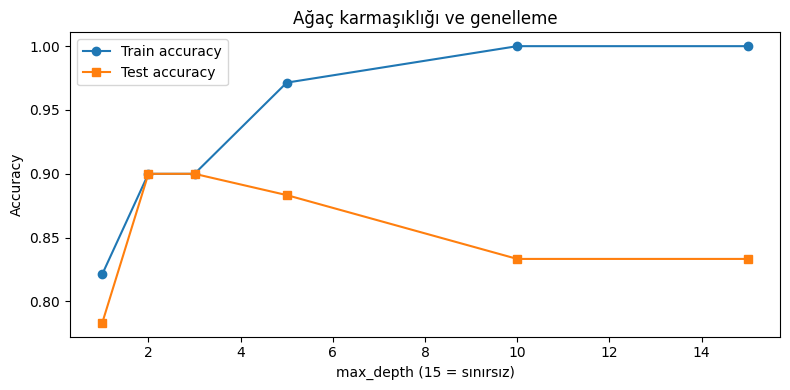

In [9]:
# İki hilal şeklinde yapay veri üreten fonksiyonu içe aktar.
from sklearn.datasets import make_moons
# 200 örnekli ve gürültülü bir sınıflandırma veri kümesi üret.
X_9, y_9 = make_moons(n_samples=200, noise=0.28, random_state=42)
# Veriyi eğitim ve test olmak üzere sınıf dengesi korunarak ayır.
X_train_9, X_test_9, y_train_9, y_test_9 = train_test_split(X_9, y_9, test_size=0.3, stratify=y_9, random_state=42)
# Farklı karmaşıklıkları denemek için ağaç derinliklerini tanımla.
depths_9 = [1, 2, 3, 5, 10, None]
# Eğitim accuracy değerlerini saklayacak boş listeyi oluştur.
train_scores_9 = []
# Test accuracy değerlerini saklayacak boş listeyi oluştur.
test_scores_9 = []
# Her aday derinlik için model kurmak üzere döngü başlat.
for depth in depths_9:
    #     Döngüdeki mevcut derinlik için yeni ağaç oluştur.
    model_9 = DecisionTreeClassifier(max_depth=depth, random_state=42)
    #     Ağacı yalnızca eğitim verisinde öğren.
    model_9.fit(X_train_9, y_train_9)
    #     Eğitim verisi üzerindeki doğruluğu listeye ekle.
    train_scores_9.append(model_9.score(X_train_9, y_train_9))
    #     Görülmemiş test verisi üzerindeki doğruluğu listeye ekle.
    test_scores_9.append(model_9.score(X_test_9, y_test_9))
# Sınırsız derinliği grafik üzerinde göstermek için sayısal bir eksen oluştur.
depth_labels_9 = [1, 2, 3, 5, 10, 15]
# Test/eğitim başarılarını karşılaştırmak için şekil oluştur.
plt.figure(figsize=(8, 4))
# Eğitim başarısını işaretli çizgi olarak görselleştir.
plt.plot(depth_labels_9, train_scores_9, marker='o', label='Train accuracy')
# Test başarısını aynı şekil üzerine ikinci çizgi olarak ekle.
plt.plot(depth_labels_9, test_scores_9, marker='s', label='Test accuracy')
# X eksenine derinlik anlamını yaz.
plt.xlabel('max_depth (15 = sınırsız)')
# Y eksenini accuracy olarak etiketle.
plt.ylabel('Accuracy')
# Grafikte hangi çizginin hangi kümeye ait olduğunu göster.
plt.legend()
# Grafiğe kısa ve açıklayıcı bir başlık ekle.
plt.title('Ağaç karmaşıklığı ve genelleme')
# Çizgilerin ve etiketlerin kesilmemesi için yerleşimi sıkıştır.
plt.tight_layout()
# Çizimi çıktı olarak göster.
plt.show()

**Mini soru:** Derinlik arttıkça train accuracy ne olur? Test accuracy mutlaka artar mı? Ağaç büyüyüp eğitim başarısı çok yüksek olsa bile neden test performansı düşebilir?

---

## 10. Regression Tree: MSE ve basamaklı tahmin

**Tür:** KOLAY — UYGULAMALI

**Amaç:** Decision Tree Regressor ile sürekli hedef tahmin etmek, Mean Squared Error kullanmak ve ağaç tahmininin parçalı sabit yapısını görselleştirmek.

Eğitim MSE: 0.250


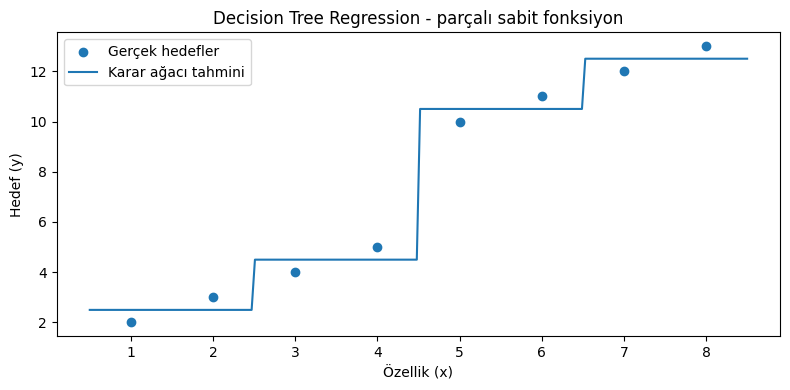

In [10]:
# Regresyon için uygun karar ağacı sınıfını içe aktar.
from sklearn.tree import DecisionTreeRegressor
# Regresyon hata ölçütü MSE hesaplama fonksiyonunu içe aktar.
from sklearn.metrics import mean_squared_error
# Tek özellikli sekiz eğitim örneğinin X değerlerini oluştur.
X_10 = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)
# Örneklere karşılık gelen sayısal hedef değerleri belirle.
y_10 = np.array([2, 3, 4, 5, 10, 11, 12, 13])
# Regresyon ağacını maksimum iki seviye derinlikle oluştur.
reg_10 = DecisionTreeRegressor(max_depth=2, random_state=42)
# Modelin giriş ve hedef değerlerini eğitimde kullan.
reg_10.fit(X_10, y_10)
# Eğitim noktaları için sayısal tahminleri hesapla.
train_pred_10 = reg_10.predict(X_10)
# Eğitim tahminlerinin ortalama kare hatasını hesapla.
mse_10 = mean_squared_error(y_10, train_pred_10)
# MSE değerini ekrana yazdır.
print(f'Eğitim MSE: {mse_10:.3f}')
# Çizimde tahminin basamaklarını görmek için aralıklı x noktaları üret.
grid_10 = np.linspace(0.5, 8.5, 200).reshape(-1, 1)
# Her çizim noktasında regresyon ağacının tahminini hesapla.
grid_pred_10 = reg_10.predict(grid_10)
# Regresyon grafiğinin figür alanını oluştur.
plt.figure(figsize=(8, 4))
# Gerçek örnekleri nokta diyagramıyla çiz.
plt.scatter(X_10[:, 0], y_10, label='Gerçek hedefler')
# Modelin tahminlerini mavi çizgi yerine varsayılan çizgiyle göster.
plt.plot(grid_10[:, 0], grid_pred_10, label='Karar ağacı tahmini')
# Grafiğin yatay eksenine X adını ver.
plt.xlabel('Özellik (x)')
# Dikey eksende sayısal hedef değerinin gösterildiğini yaz.
plt.ylabel('Hedef (y)')
# Her grafiğin açıklamasını göstermek için legend ekle.
plt.legend()
# Grafik başlığıyla parçalı sabit tahmini vurgula.
plt.title('Decision Tree Regression - parçalı sabit fonksiyon')
# Grafik elemanlarının çakışmaması için yerleşimi düzelt.
plt.tight_layout()
# Regresyon sonuçlarını göster.
plt.show()

**Mini soru:** Bu örnekte neden Accuracy yerine MSE kullanıyoruz? Ağacın derinliğini 1 ve 5 yaparsan basamak sayısı nasıl değişiyor?

---

# Öğrenciye Verilecek 3 Hafif Kapsamlı Kümeleme Görevi

Bu bölümde **Decision Tree'den farklı olarak K-Means (clustering)** kullanılacak. Amaç, öğrencilerin kodu kendilerinin yazmasıdır. Her soruda **adım adım yapılacaklar**, **hazır veri üretme kodu** ve **yorum satırlarıyla yönlendirilmiş TODO hücresi** vardır. Çözüm notebook'unda tam cevaplar bulunur.

**Hatırlatma:** K-Means `fit` sırasında sınıf etiketlerini (`y`) kullanmaz. Ölçüt olarak inertia, silhouette score ve gerekirse değerlendirme amaçlı ARI kullanılabilir.

---

## 11. K-Means: Küme sayısı seçimi, Elbow ve Silhouette

**Tür:** ÖĞRENCİ GÖREVİ — HAFİF KAPSAMLI

**Senaryo:** 240 müşterinin iki sayısal davranış özelliği var. Kaç doğal kümeye ayrıldıklarını tahmin edeceksin.

**Yapılacaklar:**
1. Veriyi üret ve iki boyutlu scatter grafikle incele.
2. `k = 2,3,4,5,6` için ayrı K-Means modelleri eğit.
3. Her `k` için `inertia_` ve `silhouette_score` değerlerini hesapla.
4. Elbow ile Silhouette grafiklerini çiz.
5. Seçtiğin `k` ile son modeli eğit; noktaları küme etiketlerine göre renklendir.
6. **Kısa yorum:** İki yöntem aynı `k` değerini mi işaret ediyor? Neden?

**Kontrol:** `X_11.shape = (240, 2)`. Beklenen doğal küme sayısı üretim gereği üçtür; metriklerden bağımsız olarak gözlemle.

In [11]:
# K-Means kümeleme algoritmasını içe aktar.
from sklearn.cluster import KMeans
# İki boyutlu yapay kümeler üretmeye yarayan fonksiyonu içe aktar.
from sklearn.datasets import make_blobs
# Küme içi tutarlılık/ayrışma ölçütü olan silhouette fonksiyonunu içe aktar.
from sklearn.metrics import silhouette_score
# Yapay ve tekrar üretilebilir 3 kümeli veri seti hazırla.
X_11, hidden_y_11 = make_blobs(n_samples=240, centers=[[-5, -2], [0, 4], [5, -1]], cluster_std=0.85, random_state=42)
# Verinin örnek ve özellik sayısını kontrol et.
print('Veri boyutu:', X_11.shape)

Veri boyutu: (240, 2)


**Yanıt alanı:** Elbow grafiğinde dirsek hangi k değerindedir? Silhouette en yüksek hangi değerde? Küme merkezleri yaklaşık nerelerde?

---

## 12. K-Means: Ölçekleme (Scaling) etkisi

**Tür:** ÖĞRENCİ GÖREVİ — HAFİF KAPSAMLI

**Senaryo:** Birinci özellik 100 ile çarpılmış, ikinci özellik küçük ölçektedir. Uzaklık temelli K-Means algoritmasının ölçekleme olmadan ve StandardScaler sonrasında nasıl davrandığını test et.

**Yapılacaklar:**
1. Sınıfları yalnızca deneyin değerlendirilmesi için verilen yapay 3 kümeli veri üret.
2. İlk özelliği 100 ile çarparak ölçü birimi farkı oluştur.
3. Ölçeklemesiz K-Means ve ölçeklenmiş K-Means kur (aynı `k=3`).
4. Her biri için Silhouette (kendi kullanıldığı özellik uzayında) hesapla.
5. Küme etiketlerini **gerçek etiketleri eğitime vermeden** ARI ile karşılaştır.
6. Küme atamalarını iki ayrı scatter grafikte incele; sonuçları yorumla.

**Önemli:** Farklı ölçeklerde hesaplanan Silhouette skorları doğrudan adil karşılaştırma olmayabilir; ARI yapay etiketler üzerinden ek tanı ölçüsüdür.

In [12]:
# Verileri ölçeklemek için StandardScaler sınıfını içe aktar.
from sklearn.preprocessing import StandardScaler
# Küme etiketleri ile gerçek yapay gruplar arasındaki benzerliği ölçmek için ARI fonksiyonunu içe aktar.
from sklearn.metrics import adjusted_rand_score
# Üç doğal kümesi bulunan tekrar üretilebilir bir veri kümesi oluştur.
X_12, true_groups_12 = make_blobs(n_samples=240, centers=[[-3, -2], [0, 3], [3, -2]], cluster_std=0.65, random_state=21)
# Orijinal verinin ayrı bir kopyasını oluştur.
X_unscaled_12 = X_12.copy()
# İlk özelliği yüz ile çarparak özellik ölçeklerini kasıtlı olarak farklılaştır.
X_unscaled_12[:, 0] = X_unscaled_12[:, 0] * 100
# Verilerin ölçeğini kontrol etmek için ilk üç satırını yazdır.
print('Ölçekleri farklı veriler:\n', X_unscaled_12[:3])

Ölçekleri farklı veriler:
 [[-9.74268152e+00  3.99659744e+00]
 [-1.89605509e+02  1.14130063e-02]
 [-4.51115459e+01  2.90210234e+00]]


**Yanıt alanı:** Neden K-Means özelliklerin ölçeğine duyarlıdır? StandardScaler bütün problemler için mutlaka daha iyi midir?

---

## 13. Iris: K-Means ile denetimsiz keşif, Decision Tree ile karşılaştırma

**Tür:** ÖĞRENCİ GÖREVİ — HAFİF KAPSAMLI

**Senaryo:** Iris çiçekleri için önce **etiketleri eğitimde kullanmadan** 3 küme bul; ardından bunun bir sınıflandırma probleminden nasıl farklı olduğunu görmek için Decision Tree eğit.

**Yapılacaklar:**
1. Iris verisini al ve stratified eğitim/test bölmesi oluştur.
2. StandardScaler'ı **yalnızca eğitim setine fit et**, test setini aynı parametrelerle dönüştür.
3. Eğitim X'i üzerinde `KMeans(n_clusters=3)` modeli eğit; `y_train` değerini K-Means'e verme.
4. Küme dağılımını ve `pd.crosstab(y_train, cluster_labels)` tablosunu oluştur.
5. ARI ve Silhouette skorlarını hesapla; ARI'de etiketleri yalnızca sonradan değerlendirme için kullan.
6. Ayrı bir `DecisionTreeClassifier(max_depth=3)` modelini **etiketlerle** eğit ve test accuracy hesapla.
7. Kısa raporda iki yöntem arasındaki *denetimli/denetimsiz* farkı açıkla.

**Not:** K-Means küme ID'leri 0, 1, 2 olarak gelebilir fakat bu ID'ler Iris sınıf kodlarıyla birebir aynı olmak zorunda değildir; bu nedenle direkt accuracy hesaplamak yanıltıcıdır.

In [13]:
# Çapraz tablo oluşturmak için Pandas kütüphanesini içe aktar.
import pandas as pd
# Iris özelliklerini ve etiketlerini veri setinden al.
X_13 = iris_2.data
# Iris tür kodlarını yalnızca değerlendirme ve denetimli model için sakla.
y_13 = iris_2.target
# Örneklerin %25’ini değerlendirme setine ayırırken sınıf oranlarını koru.
X_train_13, X_test_13, y_train_13, y_test_13 = train_test_split(X_13, y_13, test_size=0.25, stratify=y_13, random_state=42)
# Eğitim ve test boyutlarını kontrol ederek veri ayrımını doğrula.
print('Train:', X_train_13.shape, '| Test:', X_test_13.shape)

Train: (112, 4) | Test: (38, 4)


**Yanıt alanı:** K-Means'e `y_train` verilir mi? ARI ≈ 1 ne ifade eder? K-Means küme 0 mutlaka Iris sınıf 0 mıdır?

---

# Eğitmen için çözümler — 11, 12 ve 13

Aşağıdaki hücreler yalnızca **eğitmen sürümünde** görünür. Öğrenci notebook'undaki son üç görevin örnek çözümleri, ayrıntılı yorum satırlarıyla verilmiştir.

### Görev 11 çözümü — Elbow ve Silhouette

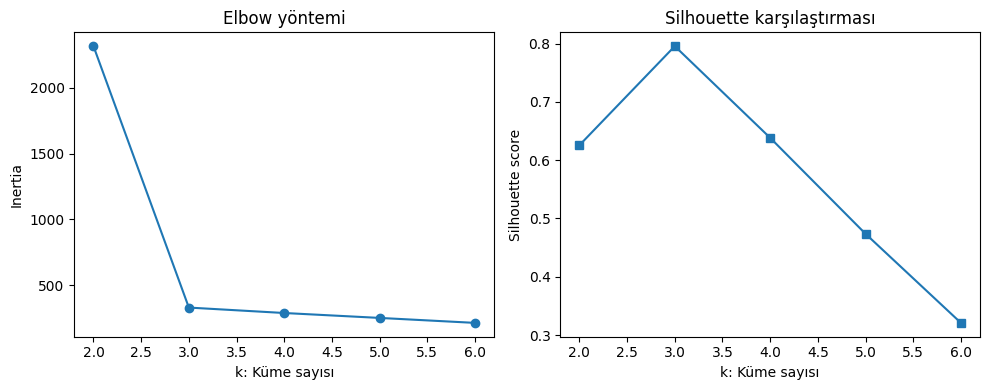

Silhouette ile seçilen k: 3


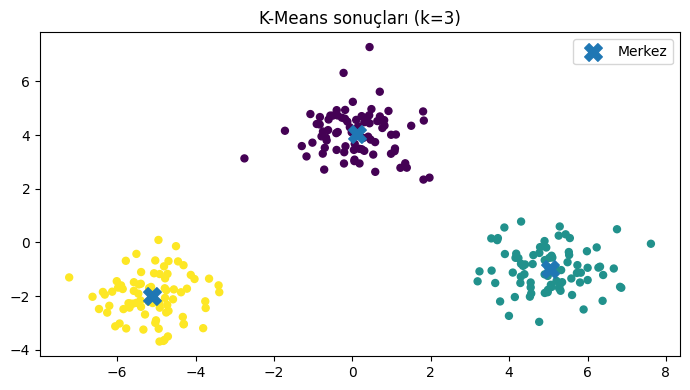

In [14]:
# Küme sayısı için araştırılacak adayları listele.
candidate_k_11 = [2, 3, 4, 5, 6]
# Elbow için inertia skorlarını saklamak üzere liste oluştur.
inertias_11 = []
# Silhouette skorlarını saklamak üzere liste oluştur.
silhouettes_11 = []
# Her aday küme sayısı için bir K-Means modeli dene.
for k in candidate_k_11:
    #     Şimdiki k değeriyle tekrar üretilebilir kümeleme modelini oluştur.
    km_11 = KMeans(n_clusters=k, random_state=42, n_init=10)
    #     Eğitimde etiket kullanmadan küme atamalarını üret.
    labels_11 = km_11.fit_predict(X_11)
    #     Küme içi kareli uzaklıklar toplamını kaydet.
    inertias_11.append(km_11.inertia_)
    #     Küme yapısının Silhouette skorunu hesaplayıp sakla.
    silhouettes_11.append(silhouette_score(X_11, labels_11))
# Aday k değerlerine göre iki grafik için geniş figür oluştur.
plt.figure(figsize=(10, 4))
# İlk grafik alanını yatay dizili 2 alanın birincisi olarak seç.
plt.subplot(1, 2, 1)
# Inertia değerlerini Elbow yöntemi için göster.
plt.plot(candidate_k_11, inertias_11, marker='o')
# Yatay eksene küme sayısı anlamını yaz.
plt.xlabel('k: Küme sayısı')
# Dikey eksene Inertia açıklamasını yaz.
plt.ylabel('Inertia')
# Grafik başlığı olarak Elbow yaz.
plt.title('Elbow yöntemi')
# İkinci grafiği sağdaki alana yerleştir.
plt.subplot(1, 2, 2)
# Silhouette skorlarını çizgi grafiğiyle göster.
plt.plot(candidate_k_11, silhouettes_11, marker='s')
# Bu grafiğin x eksenini küme sayısı olarak adlandır.
plt.xlabel('k: Küme sayısı')
# Bu grafiğin y eksenini silhouette skoru olarak adlandır.
plt.ylabel('Silhouette score')
# Bu grafiğe başlık ekle.
plt.title('Silhouette karşılaştırması')
# İki grafiğin yerleşimini düzenle.
plt.tight_layout()
# Aday k grafiklerini görüntüle.
plt.show()
# Silhouette skoru en yüksek k değerinin listedeki konumunu bul.
best_index_11 = int(np.argmax(silhouettes_11))
# Skorun işaret ettiği k değerini aday listeden seç.
best_k_11 = candidate_k_11[best_index_11]
# En yüksek silhouette seçimini ekrana yaz.
print('Silhouette ile seçilen k:', best_k_11)
# Seçilen küme sayısıyla son K-Means modelini oluştur.
final_km_11 = KMeans(n_clusters=best_k_11, random_state=42, n_init=10)
# Tüm noktaların son küme etiketlerini öğren.
cluster_labels_11 = final_km_11.fit_predict(X_11)
# Kümeleri renklendirilmiş göstermek için yeni figür başlat.
plt.figure(figsize=(7, 4))
# Müşterileri iki özelliğe göre göster; renkleri küme etiketlerinden al.
plt.scatter(X_11[:, 0], X_11[:, 1], c=cluster_labels_11, s=25)
# Küme merkezlerini belirgin işaretlerle göster.
plt.scatter(final_km_11.cluster_centers_[:, 0], final_km_11.cluster_centers_[:, 1], s=160, marker='X', label='Merkez')
# Son grafiğe hangi k kullanıldığını anlatan başlık ekle.
plt.title(f'K-Means sonuçları (k={best_k_11})')
# Grafik açıklamasını yerleştir.
plt.legend()
# Şeklin kenar boşluklarını düzelt.
plt.tight_layout()
# Son kümeleme grafiğini görüntüle.
plt.show()

**Örnek yorum:** Yapay veriler üç birbirinden ayrılmış merkezden üretildiği için Elbow genellikle 3 yakınında kırılır; Silhouette hangi k değerini işaret ediyorsa sonuçla birlikte raporlanmalıdır.

### Görev 12 çözümü — StandardScaler etkisi

Ham veri: Silhouette=0.727, ARI=0.987
Ölçekli veri: Silhouette=0.790, ARI=1.000


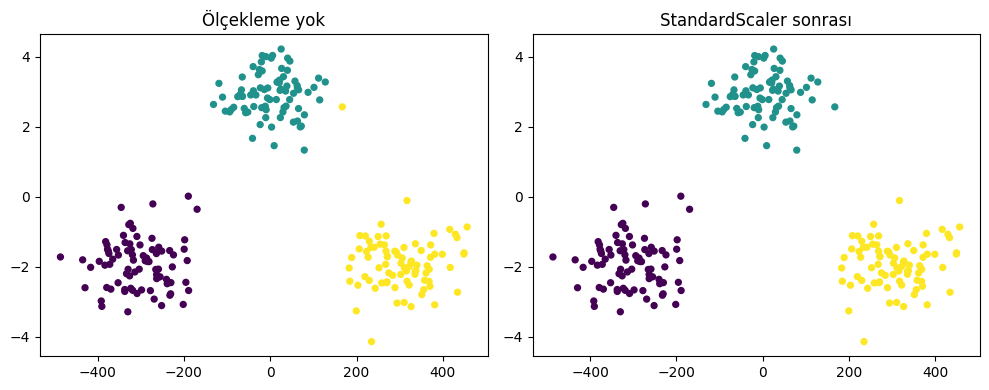

In [15]:
# Ölçekleme öncesi K-Means modelini üç küme için kur.
km_raw_12 = KMeans(n_clusters=3, random_state=42, n_init=10)
# Ham ölçekte kümeleri öğren ve tahmini küme numaralarını al.
labels_raw_12 = km_raw_12.fit_predict(X_unscaled_12)
# StandardScaler ölçekleyicisini oluştur.
scaler_12 = StandardScaler()
# Ortalama ve standart sapmayı kullanarak özellikleri aynı ölçeğe getir.
X_scaled_12 = scaler_12.fit_transform(X_unscaled_12)
# Ölçeklenmiş veri için ayrı K-Means modeli oluştur.
km_scaled_12 = KMeans(n_clusters=3, random_state=42, n_init=10)
# Ölçeklenmiş verinin küme atamalarını öğren.
labels_scaled_12 = km_scaled_12.fit_predict(X_scaled_12)
# Ham veri koordinatlarında Silhouette skorunu hesapla.
sil_raw_12 = silhouette_score(X_unscaled_12, labels_raw_12)
# Ölçeklenmiş koordinatlarda Silhouette skorunu hesapla.
sil_scaled_12 = silhouette_score(X_scaled_12, labels_scaled_12)
# Yapay referans etiketlerini yalnızca sonuç değerlendirmede kullan.
ari_raw_12 = adjusted_rand_score(true_groups_12, labels_raw_12)
# Ölçeklenmiş kümeleri referans etiketlerle ARI üzerinden karşılaştır.
ari_scaled_12 = adjusted_rand_score(true_groups_12, labels_scaled_12)
# Ham verinin skorlarını ekranda göster.
print(f'Ham veri: Silhouette={sil_raw_12:.3f}, ARI={ari_raw_12:.3f}')
# Ölçekli verinin skorlarını ekranda göster.
print(f'Ölçekli veri: Silhouette={sil_scaled_12:.3f}, ARI={ari_scaled_12:.3f}')
# İki modelin atamalarını karşılaştıracak şekil oluştur.
plt.figure(figsize=(10, 4))
# Sol tarafta ham modelin grafiği için alan seç.
plt.subplot(1, 2, 1)
# Ham modelin küme etiketlerine göre renkli noktalarını çiz.
plt.scatter(X_unscaled_12[:, 0], X_unscaled_12[:, 1], c=labels_raw_12, s=18)
# Sol grafik başlığına ham veri belirtimi ekle.
plt.title('Ölçekleme yok')
# Sağ taraftaki modelin grafiği için alan seç.
plt.subplot(1, 2, 2)
# Ölçeklenmiş modelin etiketlerini aynı ham koordinatlarda çiz.
plt.scatter(X_unscaled_12[:, 0], X_unscaled_12[:, 1], c=labels_scaled_12, s=18)
# Sağ grafik başlığına StandardScaler kullanıldığını yaz.
plt.title('StandardScaler sonrası')
# İki grafik arasındaki boşluğu düzenle.
plt.tight_layout()
# Atama farklılıklarını karşılaştırmak için grafiği göster.
plt.show()

**Örnek yorum:** K-Means Öklid uzaklığı kullandığı için büyük ölçekli özellik uzaklığı baskılar. StandardScaler her zaman tek doğru seçenek değildir; ölçümlerin fiziksel anlamı ve görev hedefi önemlidir. Farklı uzayların Silhouette değerleri doğrudan kıyaslanmamalıdır.

### Görev 13 çözümü — K-Means ve Decision Tree farkı

In [16]:
# Veri sızıntısını önlemek için eğitim üzerinde öğrenilecek ölçekleyici oluştur.
scaler_13 = StandardScaler()
# Sadece eğitim verisi üzerinden ortalama ve standart sapmayı öğren.
X_train_scaled_13 = scaler_13.fit_transform(X_train_13)
# Test verisini eğitimden öğrenilen ölçek parametreleriyle dönüştür.
X_test_scaled_13 = scaler_13.transform(X_test_13)
# Etiket görmeden üç küme oluşturacak K-Means modelini başlat.
km_13 = KMeans(n_clusters=3, random_state=42, n_init=10)
# Eğitim özelliklerini kümelemek için yalnızca X kullan; y verme.
clusters_13 = km_13.fit_predict(X_train_scaled_13)
# Bulunan üç kümenin kaç örnek içerdiğini hesapla.
cluster_ids_13, counts_13 = np.unique(clusters_13, return_counts=True)
# Küme büyüklüklerini yazdır.
print('Küme büyüklükleri:', dict(zip(cluster_ids_13, counts_13)))
# Gerçek tür ve K-Means küme numaralarını yalnızca incelemek için tabloya dök.
ct_13 = pd.crosstab(y_train_13, clusters_13, rownames=["Gerçek tür"], colnames=["Bulunan küme"])
# Çapraz tabloyu ekrana yazdır.
print(ct_13)
# Gerçek tür etiketlerini yalnızca değerlendirmede kullanarak ARI hesapla.
ari_13 = adjusted_rand_score(y_train_13, clusters_13)
# Kümelerin geometrik uyumunu Silhouette skoruyla değerlendir.
sil_13 = silhouette_score(X_train_scaled_13, clusters_13)
# K-Means değerlendirme metriklerini ekranda göster.
print(f'K-Means train ARI={ari_13:.3f}; train silhouette={sil_13:.3f}')
# Etiketle eğitilen denetimli bir Decision Tree sınıflandırıcısı oluştur.
tree_13 = DecisionTreeClassifier(max_depth=3, random_state=42)
# Karar ağacını eğitim özellikleri ve gerçek etiketlerle eğit.
tree_13.fit(X_train_13, y_train_13)
# Test çiçeklerinin türlerini denetimli ağaçla tahmin et.
test_pred_13 = tree_13.predict(X_test_13)
# Karar ağacının görülmemiş test kümesindeki doğruluğunu hesapla.
acc_13 = accuracy_score(y_test_13, test_pred_13)
# Decision Tree için test accuracy sonucunu ekranda göster.
print(f'Decision Tree test accuracy={acc_13:.3f}')

Küme büyüklükleri: {np.int32(0): np.int64(46), np.int32(1): np.int64(38), np.int32(2): np.int64(28)}
Bulunan küme   0   1   2
Gerçek tür              
0              0  38   0
1             33   0   4
2             13   0  24
K-Means train ARI=0.650; train silhouette=0.495
Decision Tree test accuracy=0.895


**Örnek yorum:** K-Means'in eğitimdeki amacı etiketsiz gözlemleri geometrik benzerliğe göre gruplamaktır; küme numaralarının sınıf isimleriyle eşleşmesi gerekmez. ARI gerçek etiketlerle sonradan değerlendirilen küme uyuşmasını, Decision Tree accuracy ise görülmemiş veride etiket tahminini ölçer. Aynı metrikler olmadığı için değerler doğrudan bir üstünlük sıralaması oluşturmaz.

---

## Kontrol listesi ve temel kavramlar

- [ ] Decision Tree ile `fit` ve `predict` yaptım.
- [ ] Train/test ayrımının neden gerekli olduğunu anlatabiliyorum.
- [ ] Entropy ve Gini değerlerini sınıf sayılarından hesaplayabiliyorum.
- [ ] Information Gain'in neden **ağırlıklı** bölme entropisiyle hesaplandığını biliyorum.
- [ ] `max_depth` ile overfitting ilişkisini inceledim.
- [ ] Sınıflandırmada accuracy, regresyonda MSE kullandım.
- [ ] Elbow ve Silhouette ile küme sayısı değerlendirdim.
- [ ] Ölçeklemenin K-Means üzerindeki etkisini inceledim.
- [ ] K-Means ile Decision Tree'nin denetimsiz/denetimli farkını açıklayabiliyorum.

**En önemli formüller**

- Entropy: \(H=-\sum_i p_i\log_2p_i\)
- Gini: \(G=1-\sum_i p_i^2\)
- Information Gain: \(IG=H(ana)-\sum_j\frac{N_j}{N}H(çocuk_j)\)
- MSE: \(\frac{1}{N}\sum_i(y_i-\hat y_i)^2\)